###Bước 1) Khai báo thư viện và đọc ảnh

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


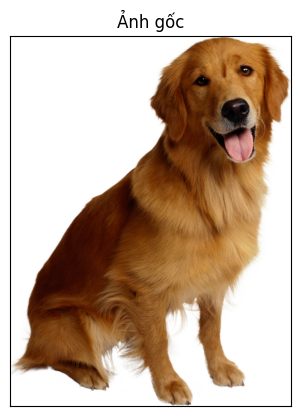

In [1]:
def in_thong_tin():
    print("Họ và tên: Nguyễn Gia Huy")
    print("Mã sinh viên: 6451071027")
    print("-" * 30)

in_thong_tin()

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
import os
%matplotlib inline

ten_anh = 'dog.png'     # đổi thành tên ảnh của bạn

if os.path.exists(ten_anh):
    image = Image.open(ten_anh).convert('RGB')
else:
    # Ảnh dự phòng (gradient màu) để chạy thử khi chưa có ảnh
    print("Không thấy file", ten_anh, "- dùng ảnh tạo tự động")
    h, w = 300, 450
    gx, gy = np.meshgrid(np.linspace(0, 255, w), np.linspace(0, 255, h))
    image = Image.fromarray(np.dstack([gx, gy, 255 - gx]).astype(np.uint8))

axes = plt.axes(xticks=[], yticks=[])
axes.imshow(image)
plt.title('Ảnh gốc')
plt.show()

###Bước 2) Chuyển ảnh thành mảng số và lấy kích thước

In [2]:
in_thong_tin()

imarr = np.array(image)
rows = imarr.shape[0]
cols = imarr.shape[1]

print("Kích thước mảng ảnh:", imarr.shape)
print("Chiều cao:", rows, "| Chiều rộng:", cols)
print("Số pixel:", rows * cols)
print("Số màu khác nhau trong ảnh gốc:", len(np.unique(imarr.reshape(-1, 3), axis=0)))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Kích thước mảng ảnh: (3006, 2284, 3)
Chiều cao: 3006 | Chiều rộng: 2284
Số pixel: 6865704
Số màu khác nhau trong ảnh gốc: 110042


###Bước 3) Chuẩn hóa và chuyển mảng về dạng 2 chiều

In [3]:
in_thong_tin()

data = imarr / 255.0
data = data.reshape(rows * cols, 3)
print("Kích thước dữ liệu sau reshape:", data.shape)

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Kích thước dữ liệu sau reshape: (6865704, 3)


###Bước 4) Gom cụm k-Means với 32 màu

In [4]:
in_thong_tin()

so_mau = 32
kmeans = KMeans(n_clusters=so_mau, max_iter=300, n_init=3, random_state=42)
kmeans.fit(data)
new_colors = kmeans.cluster_centers_[kmeans.predict(data)]

print("Số màu sau khi gom cụm:", so_mau)
print("Bảng 32 màu đại diện (RGB 0-255):")
print((kmeans.cluster_centers_ * 255).astype(int))

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Số màu sau khi gom cụm: 32
Bảng 32 màu đại diện (RGB 0-255):
[[125  72  28]
 [247 245 241]
 [205 158 101]
 [170 117  61]
 [ 66  17   2]
 [ 92  39   6]
 [225 211 196]
 [156  96  35]
 [187 142  94]
 [214 191 166]
 [190 167 146]
 [254 254 254]
 [ 13   7   6]
 [110  60  22]
 [153 118  91]
 [138  86  39]
 [179 130  76]
 [ 49  11   3]
 [237 230 221]
 [178 143 118]
 [ 79  28   3]
 [154 104  53]
 [213 175 122]
 [ 72  52  45]
 [105  49   9]
 [196 142  78]
 [123  62  12]
 [173 111  43]
 [214 147 142]
 [187 127  58]
 [118  88  70]
 [140  78  22]]


###Bước 5) Khôi phục dạng ảnh và so sánh với ảnh gốc

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


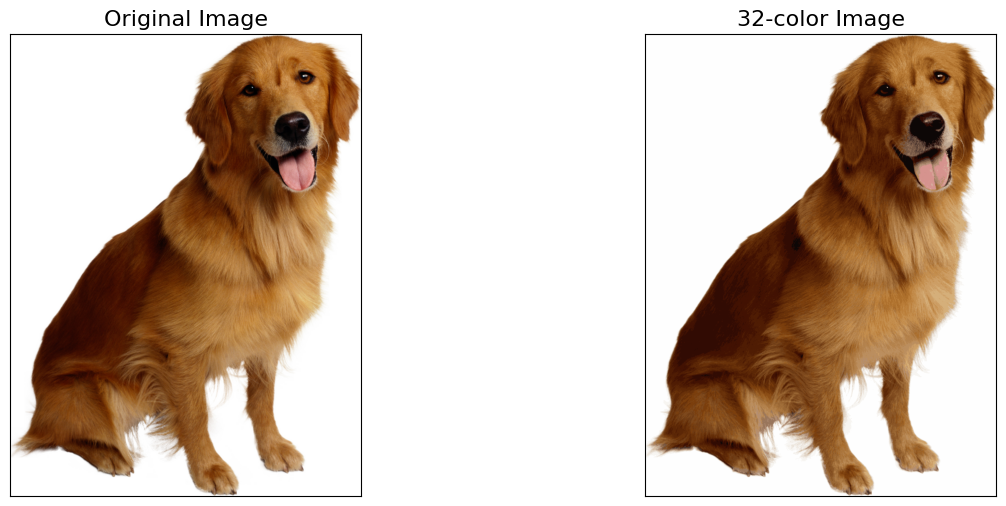

In [5]:
in_thong_tin()

img_recolored = new_colors.reshape(imarr.shape)

fig, ax = plt.subplots(1, 2, figsize=(16, 6),
                       subplot_kw=dict(xticks=[], yticks=[]))
fig.subplots_adjust(wspace=0.05)
ax[0].imshow(image)
ax[0].set_title('Original Image', size=16)
ax[1].imshow(img_recolored)
ax[1].set_title(f'{so_mau}-color Image', size=16)
plt.show()

###Bước 6) Lưu ảnh kết quả xuống đĩa và so sánh dung lượng

In [6]:
in_thong_tin()

img_out = (img_recolored * 255).astype(np.uint8)
new_img = Image.fromarray(img_out)
new_img.save('compressed_img2.png')

# Lưu thêm bản gốc dạng png để so sánh công bằng
image.save('original_rgb.png')

kt_goc = os.path.getsize('original_rgb.png') / 1024
kt_moi = os.path.getsize('compressed_img2.png') / 1024
print(f"Dung lượng ảnh gốc    : {kt_goc:.1f} KB")
print(f"Dung lượng ảnh 32 màu : {kt_moi:.1f} KB")
print(f"Giảm: {(1 - kt_moi / kt_goc) * 100:.1f}%")

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------
Dung lượng ảnh gốc    : 4765.4 KB
Dung lượng ảnh 32 màu : 1306.6 KB
Giảm: 72.6%


###Bước 7) So sánh các mức số màu khác nhau

Họ và tên: Nguyễn Gia Huy
Mã sinh viên: 6451071027
------------------------------


/tmp/ipykernel_5791/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


  4 màu: 144.7 KB


/tmp/ipykernel_5791/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


 16 màu: 488.8 KB


/tmp/ipykernel_5791/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


 32 màu: 761.2 KB


/tmp/ipykernel_5791/425070929.py:16: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  pal = Image.fromarray(nhan, mode='P')


 64 màu: 1015.1 KB


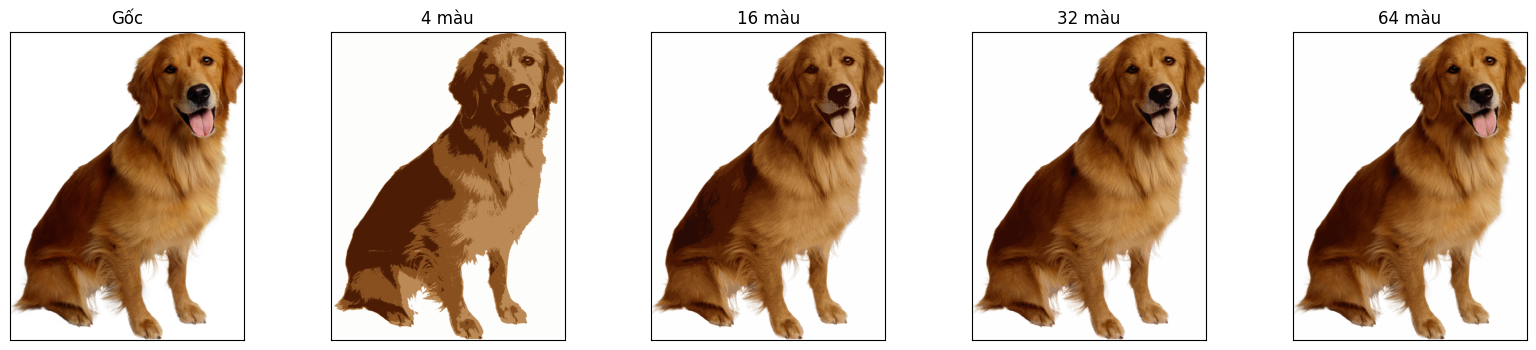

In [7]:
in_thong_tin()

cac_muc = [4, 16, 32, 64]
fig, axes = plt.subplots(1, len(cac_muc) + 1, figsize=(20, 4),
                         subplot_kw=dict(xticks=[], yticks=[]))
axes[0].imshow(image); axes[0].set_title('Gốc')

for ax, k in zip(axes[1:], cac_muc):
    km = KMeans(n_clusters=k, max_iter=300, n_init=1, random_state=42).fit(data)
    anh_k = km.cluster_centers_[km.labels_].reshape(imarr.shape)
    ax.imshow(anh_k)
    ax.set_title(f'{k} màu')

    # Lưu dạng png có bảng màu để thấy rõ dung lượng giảm
    nhan = km.labels_.reshape(rows, cols).astype(np.uint8)
    pal = Image.fromarray(nhan, mode='P')
    pal.putpalette((km.cluster_centers_ * 255).astype(np.uint8).flatten().tolist())
    ten_file = f'compressed_{k}colors.png'
    pal.save(ten_file)
    print(f"{k:>3} màu: {os.path.getsize(ten_file) / 1024:.1f} KB")
plt.show()